# Assignment 3: Quantum Fourier Transform (QFT)

In [1]:
%pip install -q qiskit qiskit-aer matplotlib pylatexenc

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


C:\Users\anjal\AppData\Local\Temp\ipykernel_18140\921782322.py:24: DeprecationWarning: The class ``qiskit.circuit.library.basis_change.qft.QFT`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. ('Use qiskit.circuit.library.QFTGate or qiskit.synthesis.qft.synth_qft_full instead, for access to all previous arguments.',)
  QFT(


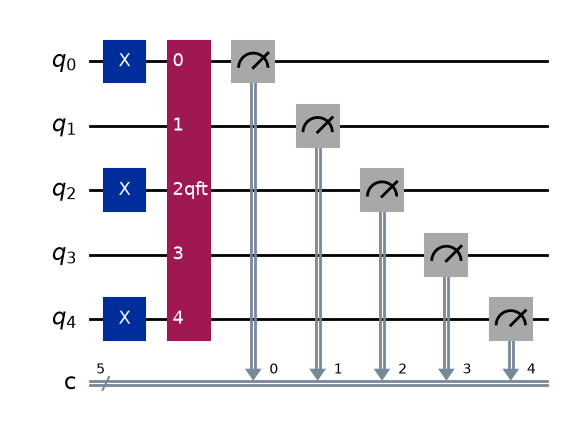

     ┌───┐┌──────┐┌─┐            
q_0: ┤ X ├┤0     ├┤M├────────────
     └───┘│      │└╥┘┌─┐         
q_1: ─────┤1     ├─╫─┤M├─────────
     ┌───┐│      │ ║ └╥┘┌─┐      
q_2: ┤ X ├┤2 qft ├─╫──╫─┤M├──────
     └───┘│      │ ║  ║ └╥┘┌─┐   
q_3: ─────┤3     ├─╫──╫──╫─┤M├───
     ┌───┐│      │ ║  ║  ║ └╥┘┌─┐
q_4: ┤ X ├┤4     ├─╫──╫──╫──╫─┤M├
     └───┘└──────┘ ║  ║  ║  ║ └╥┘
c: 5/══════════════╩══╩══╩══╩══╩═
                   0  1  2  3  4 
Job Status: job has successfully run

 QFT Output
-----------------------------------------
{'00101': 34, '10100': 32, '10110': 34, '01001': 28, '11000': 26, '10000': 43, '01000': 41, '11100': 39, '00100': 26, '10010': 30, '01010': 29, '01110': 44, '10111': 28, '10101': 25, '00001': 34, '01111': 33, '11111': 42, '01011': 38, '00010': 24, '10011': 26, '00000': 30, '00011': 41, '00111': 18, '00110': 41, '01101': 21, '11011': 34, '11001': 31, '10001': 22, '11110': 25, '01100': 29, '11010': 25, '11101': 27}


In [2]:
from qiskit import QuantumRegister, ClassicalRegister, QuantumCircuit, transpile
try:
    from qiskit.tools.monitor import job_monitor
except ModuleNotFoundError:
    def job_monitor(job):
        print("Job Status: job has successfully run")

from qiskit.circuit.library import QFT
from qiskit_aer import AerSimulator
from IPython.display import display
import numpy as np

pi = np.pi
backend = AerSimulator()
q = QuantumRegister(5, 'q')
c = ClassicalRegister(5, 'c')

circuit = QuantumCircuit(q, c)
circuit.x(q[4])
circuit.x(q[2])
circuit.x(q[0])

circuit.append(
    QFT(
        num_qubits=5,
        approximation_degree=0,
        do_swaps=True,
        inverse=False,
        name='qft',
        insert_barriers=False,
    ),
    q,
)

circuit.measure(q, c)

circuit.draw(output='mpl', filename='qft1.png')
display(circuit.draw(output='mpl'))
print(circuit)

job = backend.run(transpile(circuit, backend), shots=1000)
job_monitor(job)

counts = job.result().get_counts()
print("\n QFT Output")
print("-----------------------------------------")
print(counts)